# New Fit (Multi-class) — Fruits CNN

This notebook adapts the reference `Fit.ipynb` for four-class fruit recognition.

**Classes:** apple, banana, mango, orange  
**Input:** `dataset/prepared/{train,validation,test}/` from the image-generator notebook.  
**Output model:** `models/fruit_cnn_model.keras`

## CNN architecture adapted from the reference

The reference model uses:
- Conv2D(32) → MaxPooling
- Conv2D(64) → MaxPooling → Dropout(0.25)
- Flatten → Dense(128) → Dropout(0.5)
- Binary output: Dense(1, sigmoid)

Our multi-class version keeps this architecture and changes the final layer to `Dense(4, activation="softmax")`, with `sparse_categorical_crossentropy` loss.

In [1]:
from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *
from tensorflow.keras.callbacks import *
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

PROJECT_DIR = Path.cwd()
PREPARED_DIR = PROJECT_DIR / "dataset/prepared"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

MODEL_PATH = MODEL_DIR / "fruit_cnn_model.keras"

CLASS_NAMES = ["apple", "banana", "mango", "orange"]
IMAGE_SIZE, BATCH_SIZE, EPOCHS, SEED = (128, 128), 32, 20, 42

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Dataset:", PREPARED_DIR)
print("Model:", MODEL_PATH)

TensorFlow: 2.21.0
Dataset: C:\Users\fhv\rahat-codes\Multilevel Classification CNN Model Project\dataset\prepared
Model: C:\Users\fhv\rahat-codes\Multilevel Classification CNN Model Project\models\fruit_cnn_model.keras


## 1. Load training, validation and test images

The directory generator assigns integer labels from folder names. We explicitly verify the class order so prediction labels match the model outputs.

Only rescaling is used here because augmentation has already been saved in the training folder by the previous notebook.

In [2]:
data_generator = ImageDataGenerator(rescale=1./255)

def load_data(split, shuffle=False):
    return data_generator.flow_from_directory(
        PREPARED_DIR / split,
        target_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="sparse",
        shuffle=shuffle,
        seed=SEED
    )

train_data = load_data("train", shuffle=True)
validation_data = load_data("validation")
test_data = load_data("test")

print("Class indices:", train_data.class_indices)

expected = {name: i for i, name in enumerate(CLASS_NAMES)}
assert train_data.class_indices == expected, "Unexpected class order!"

Found 228 images belonging to 4 classes.
Found 8 images belonging to 4 classes.
Found 9 images belonging to 4 classes.
Class indices: {'apple': 0, 'banana': 1, 'mango': 2, 'orange': 3}


## 2. Build the multi-class CNN

This is the reference Sequential CNN adapted from binary to four classes. The final softmax layer returns four class probabilities that sum to approximately 1.

In [3]:
def build_multiclass_model(input_shape=(128, 128, 3), num_classes=4):
    model = Sequential([
        Input(shape=input_shape),

        Conv2D(32, (3, 3), activation="relu"),
        MaxPooling2D(pool_size=(2, 2)),

        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.5),

        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_multiclass_model(
    input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3),
    num_classes=len(CLASS_NAMES)
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,836 (28.20 MB)

 Trainable params: 7,392,836 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Configure training callbacks

The reference trains for 20 epochs. We keep 20 as the maximum and add:
- ModelCheckpoint: save the best validation-accuracy model.
- EarlyStopping: stop if validation loss stops improving.
- ReduceLROnPlateau: lower the learning rate when progress plateaus.

In [4]:
callbacks = [
    ModelCheckpoint(MODEL_PATH, monitor="val_accuracy", mode="max",
                    save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=5,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                      patience=2, min_lr=1e-6, verbose=1)
]

## 4. Train the CNN

Training uses the augmented training folder. Validation data remains unaugmented and is used to monitor generalization.

In [5]:
history = model.fit(
    train_data,
    epochs=EPOCHS,
    validation_data=validation_data,
    callbacks=callbacks
)

print("Training complete. Best model:", MODEL_PATH)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4342 - loss: 1.2824
Epoch 1: val_accuracy improved from None to 0.62500, saving model to C:\Users\fhv\rahat-codes\Multilevel Classification CNN Model Project\models\fruit_cnn_model.keras

Epoch 1: finished saving model to C:\Users\fhv\rahat-codes\Multilevel Classification CNN Model Project\models\fruit_cnn_model.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.4342 - loss: 1.2824 - val_accuracy: 0.6250 - val_loss: 0.8137 - learning_rate: 0.0010
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6579 - loss: 0.7670
Epoch 2: val_accuracy improved from 0.62500 to 0.75000, saving model to C:\Users\fhv\rahat-codes\Multilevel Classification CNN Model Project\models\fruit_cnn_model.keras

Epoch 2: finished saving model to C:\Users\fhv\rahat-codes\Multilevel Classification CNN Model Project\models\fruit_cnn_model.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.6579 - loss: 0.7670 - val_accuracy: 0.7500 - va

## 5. Plot training and validation history

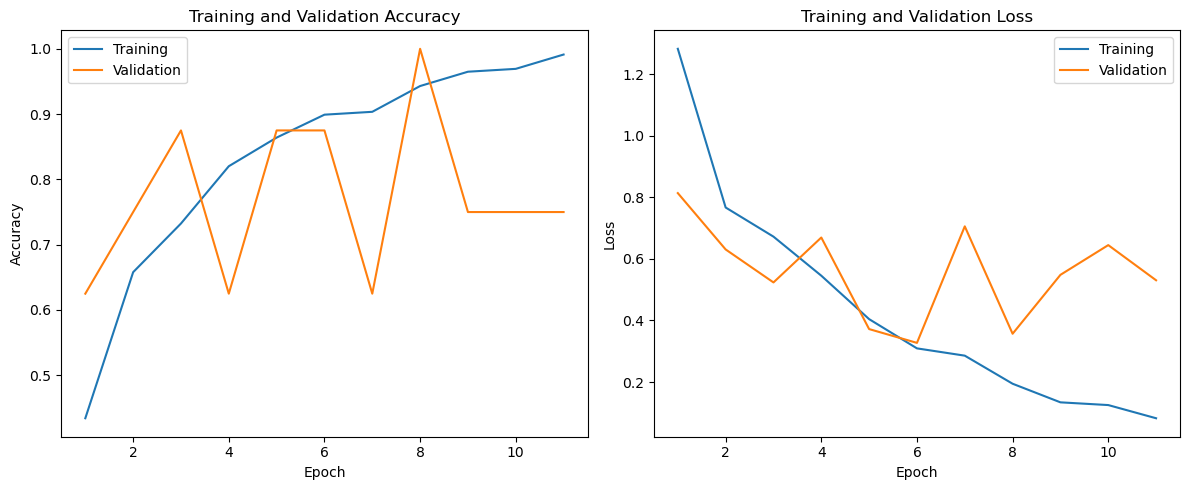

In [7]:
h = history.history
epochs = range(1, len(h["accuracy"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for i, metric in enumerate(["accuracy", "loss"]):
    ax[i].plot(epochs, h[metric], label="Training")
    ax[i].plot(epochs, h[f"val_{metric}"], label="Validation")
    ax[i].set(title=f"Training and Validation {metric.title()}",
              xlabel="Epoch", ylabel=metric.title())
    ax[i].legend()

plt.tight_layout()
plt.show()

## 6. Evaluate on the untouched official test partition

The official Fruits-360 test set was not used for training, augmentation, or validation. This is the final evaluation partition.

In [11]:
import numpy as np
best_model = tf.keras.models.load_model(MODEL_PATH)

loss, accuracy = best_model.evaluate(test_data)
print(f"Test Loss: {loss:.4f} | Accuracy: {accuracy * 100:.2f}%")

test_data.reset()
y_pred = np.argmax(best_model.predict(test_data), axis=1)

print(classification_report(
    test_data.classes, y_pred,
    target_names=CLASS_NAMES, digits=4, zero_division=0
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.7778 - loss: 0.3440
Test Loss: 0.3440 | Accuracy: 77.78%
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
              precision    recall  f1-score   support

       apple     1.0000    1.0000    1.0000         3
      banana     0.5000    0.5000    0.5000         2
       mango     0.5000    0.5000    0.5000         2
      orange     1.0000    1.0000    1.0000         2

    accuracy                         0.7778         9
   macro avg     0.7500    0.7500    0.7500         9
weighted avg     0.7778    0.7778    0.7778         9



## 7. Save final model

The best checkpoint is already saved at `models/fruit_cnn_model.keras`. We also save the final in-memory model to the same path after restoring the best weights.

In [ ]:
best_model.save(MODEL_PATH)
print("Model saved successfully:", MODEL_PATH)
print("Output classes:", CLASS_NAMES)
print("Input image size:", IMAGE_SIZE)

## 8. Next notebook

Open `Predict.ipynb` to load `models/fruit_cnn_model.keras` and classify a new fruit photograph.

Remember: a strong score on Fruits-360 reflects performance on its controlled image style. Test a few real photographs from your phone separately to understand how well the model generalizes.